In [17]:
import os
import numpy as np
import pandas as pd
import json
import SimpleITK as sitk
import matplotlib.pyplot as plt

# Paths (corrected)
RESAMPLED_SCANS_DIR = "../Desktop/project - Copy/preprocessed/resampled"
CANDIDATES_CSV = "../Desktop/project - Copy/data/candidates.csv"
ANNOTATIONS_CSV = "../Desktop/project - Copy/data/annotations.csv"

# Output file
OUTPUT_JSON ="../Desktop/project - Copy/notebooks/detection_dataset.json"

BOX_SIZE = [32, 32, 32]


In [19]:
# Cell 2

# Load candidates.csv (scan_id, coordX, coordY, coordZ, label)
candidates_df = pd.read_csv(CANDIDATES_CSV)

# Load annotations.csv (scan_id, coordX, coordY, coordZ, diameter)
annotations_df = pd.read_csv(ANNOTATIONS_CSV)

print(f"Loaded {len(candidates_df)} candidates.")
print(f"Loaded {len(annotations_df)} ground-truth nodules.")


Loaded 754975 candidates.
Loaded 1186 ground-truth nodules.


In [21]:
# Cell 3

# Simple helper: Euclidean distance
def compute_distance(p1, p2):
    return np.linalg.norm(np.array(p1) - np.array(p2))


In [23]:
# Corrected Cell 4

available_scans = set()

for fname in os.listdir(RESAMPLED_SCANS_DIR):
    if fname.endswith("_resampled.mhd"):
        clean_name = fname.replace("_resampled.mhd", "")
        available_scans.add(clean_name)

print(f"Available scans after cleaning: {len(available_scans)}")

detection_dataset = []

for idx, row in candidates_df.iterrows():
    scan_id = row["seriesuid"]
    
    if scan_id not in available_scans:
        continue  # Skip if scan not available

    cand_x, cand_y, cand_z = row["coordX"], row["coordY"], row["coordZ"]
    
    strict_label = 0
    loose_label = 0
    
    # Find all GT nodules for the same scan
    gt_nodules = annotations_df[annotations_df["seriesuid"] == scan_id]
    
    for _, gt in gt_nodules.iterrows():
        gt_x, gt_y, gt_z = gt["coordX"], gt["coordY"], gt["coordZ"]
        distance = compute_distance([cand_x, cand_y, cand_z], [gt_x, gt_y, gt_z])
        
        if distance < 5.0:
            strict_label = 1
        if distance < 10.0:
            loose_label = 1
    
    detection_dataset.append({
        "scan_id": scan_id,
        "center": [cand_z, cand_y, cand_x],  # z, y, x
        "box_size": BOX_SIZE,
        "strict_label": strict_label,
        "loose_label": loose_label
    })

print(f"Detection dataset created with {len(detection_dataset)} candidates linked to available scans.")


Available scans after cleaning: 888
Detection dataset created with 754975 candidates linked to available scans.


In [7]:
# Cell 5

# Save as JSON
with open(OUTPUT_JSON, "w") as f:
    json.dump(detection_dataset, f, indent=4)

print(f"Detection dataset saved to {OUTPUT_JSON}")


Detection dataset saved to ../Desktop/project - Copy/notebooks/detection_dataset.json


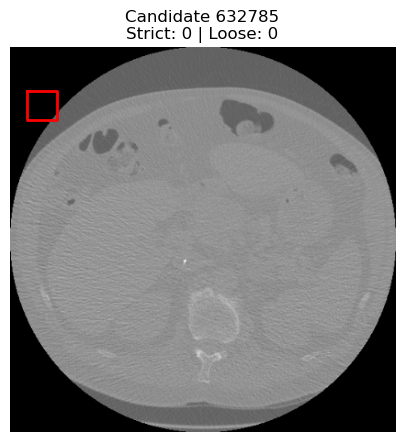

In [61]:
# Cell 6 (load MHD)

def visualize_candidate(candidate_idx=None):
    import random
    
    available_candidates = []
    
    # Find candidates whose scan file exists
    for idx, cand in enumerate(detection_dataset):
        scan_id = cand["scan_id"]
        scan_path = os.path.join(RESAMPLED_SCANS_DIR, f"{scan_id}_resampled.mhd")
        if os.path.exists(scan_path):
            available_candidates.append(idx)
    
    if not available_candidates:
        print("No available candidates found!")
        return
    
    if candidate_idx is None:
        candidate_idx = random.choice(available_candidates)
    else:
        if candidate_idx not in available_candidates:
            print(f"Candidate {candidate_idx} not available.")
            return
    
    candidate = detection_dataset[candidate_idx]
    scan_id = candidate["scan_id"]
    scan_path = os.path.join(RESAMPLED_SCANS_DIR, f"{scan_id}_resampled.mhd")
    
    # Load scan using SimpleITK
    scan = sitk.ReadImage(scan_path)
    scan_array = sitk.GetArrayFromImage(scan)  # shape: (depth, height, width)

    center_z, center_y, center_x = candidate["center"]
    slice_idx = int(round(center_z))
    slice_idx = np.clip(slice_idx, 0, scan_array.shape[0]-1)

    plt.figure(figsize=(10,5))
    plt.imshow(scan_array[slice_idx], cmap='gray')
    
    box_half = 16
    plt.plot(
        [center_x - box_half, center_x + box_half, center_x + box_half, center_x - box_half, center_x - box_half],
        [center_y - box_half, center_y - box_half, center_y + box_half, center_y + box_half, center_y - box_half],
        color="red", linewidth=2
    )
    
    plt.title(f"Candidate {candidate_idx}\nStrict: {candidate['strict_label']} | Loose: {candidate['loose_label']}")
    plt.axis('off')
    plt.show()

# Example usage
visualize_candidate()


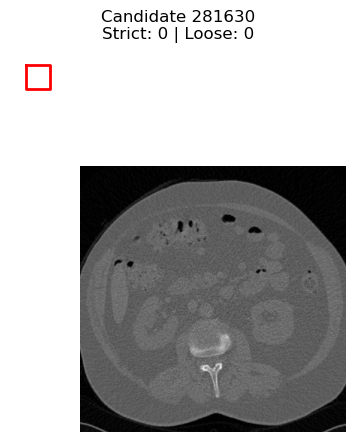

In [63]:
    visualize_candidate()


In [10]:
print(len(detection_dataset))


754975


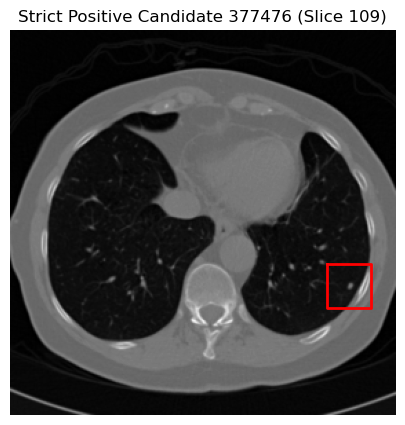

In [77]:
import random
import matplotlib.pyplot as plt


import random
import numpy as np
import matplotlib.pyplot as plt

def world_to_voxel(world_coord, origin, spacing):
    stretched_voxel_coord = np.absolute(world_coord - origin)
    voxel_coord = stretched_voxel_coord / spacing
    return voxel_coord

def visualize_random_strict_candidate():
    strict_candidates = [idx for idx, cand in enumerate(detection_dataset) if cand["strict_label"] == 1]
    
    if not strict_candidates:
        print("❌ No strict positive candidates found.")
        return
    
    attempt = 0
    while attempt < 10:
        candidate_idx = random.choice(strict_candidates)
        candidate = detection_dataset[candidate_idx]
        scan_id = candidate["scan_id"]
        
        scan_path = os.path.join(RESAMPLED_SCANS_DIR, f"{scan_id}_resampled.mhd")
        if not os.path.exists(scan_path):
            attempt += 1
            continue
        
        # Load scan
        scan = sitk.ReadImage(scan_path)
        scan_array = sitk.GetArrayFromImage(scan)
        origin = np.array(scan.GetOrigin())[::-1]    # reverse order: z, y, x
        spacing = np.array(scan.GetSpacing())[::-1]  # reverse order: z, y, x

        # World → Voxel
        center_world = np.array(candidate["center"])  # (z,y,x) in mm
        center_voxel = world_to_voxel(center_world, origin, spacing)

        slice_idx = int(round(center_voxel[0]))
        
        # 🔵 New filter: skip slices too close to edges
        if slice_idx < 10 or slice_idx > scan_array.shape[0] - 10:
            attempt += 1
            continue
        
        slice_idx = np.clip(slice_idx, 0, scan_array.shape[0]-1)
        
        plt.figure(figsize=(10,5))
        plt.imshow(scan_array[slice_idx], cmap="gray")
        
        box_half = 16
        center_y, center_x = center_voxel[1], center_voxel[2]
        
        plt.plot(
            [center_x - box_half, center_x + box_half, center_x + box_half, center_x - box_half, center_x - box_half],
            [center_y - box_half, center_y - box_half, center_y + box_half, center_y + box_half, center_y - box_half],
            color="red", linewidth=2
        )
        
        plt.title(f"Strict Positive Candidate {candidate_idx} (Slice {slice_idx})")
        plt.axis('off')
        plt.show()
        return
    
    print("❌ Couldn't find a good strict candidate after 10 attempts.")

   
visualize_random_strict_candidate()


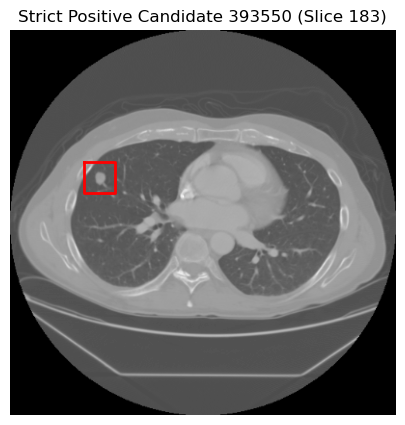

In [101]:
import random
import matplotlib.pyplot as plt


import random
import numpy as np
import matplotlib.pyplot as plt

def world_to_voxel(world_coord, origin, spacing):
    stretched_voxel_coord = np.absolute(world_coord - origin)
    voxel_coord = stretched_voxel_coord / spacing
    return voxel_coord

def visualize_random_strict_candidate():
    strict_candidates = [idx for idx, cand in enumerate(detection_dataset) if cand["strict_label"] ==1 ]
    
    if not strict_candidates:
        print("❌ No strict positive candidates found.")
        return
    
    attempt = 0
    while attempt < 10:
        candidate_idx = random.choice(strict_candidates)
        candidate = detection_dataset[candidate_idx]
        scan_id = candidate["scan_id"]
        
        scan_path = os.path.join(RESAMPLED_SCANS_DIR, f"{scan_id}_resampled.mhd")
        if not os.path.exists(scan_path):
            attempt += 1
            continue
        
        # Load scan
        scan = sitk.ReadImage(scan_path)
        scan_array = sitk.GetArrayFromImage(scan)
        origin = np.array(scan.GetOrigin())[::-1]    # reverse order: z, y, x
        spacing = np.array(scan.GetSpacing())[::-1]  # reverse order: z, y, x

        # World → Voxel
        center_world = np.array(candidate["center"])  # (z,y,x) in mm
        center_voxel = world_to_voxel(center_world, origin, spacing)

        slice_idx = int(round(center_voxel[0]))
        
        # 🔵 New filter: skip slices too close to edges
        if slice_idx < 10 or slice_idx > scan_array.shape[0] - 10:
            attempt += 1
            continue
        
        slice_idx = np.clip(slice_idx, 0, scan_array.shape[0]-1)
        
        plt.figure(figsize=(10,5))
        plt.imshow(scan_array[slice_idx], cmap="gray")
        
        box_half = 16
        center_y, center_x = center_voxel[1], center_voxel[2]
        
        plt.plot(
            [center_x - box_half, center_x + box_half, center_x + box_half, center_x - box_half, center_x - box_half],
            [center_y - box_half, center_y - box_half, center_y + box_half, center_y + box_half, center_y - box_half],
            color="red", linewidth=2
        )
        
        plt.title(f"Strict Positive Candidate {candidate_idx} (Slice {slice_idx})")
        plt.axis('off')
        plt.show()
        return
    
    print("❌ Couldn't find a good strict candidate after 10 attempts.")

   
visualize_random_strict_candidate()


In [12]:
import pandas as pd

# Convert list of dicts to DataFrame
detection_dataset_df = pd.DataFrame(detection_dataset)

# Save as CSV
detection_dataset_df.to_csv("../Desktop/project - Copy/preprocessed/detection_dataset.csv", index=False)

print("✅ detection_dataset.csv saved!")


✅ detection_dataset.csv saved!


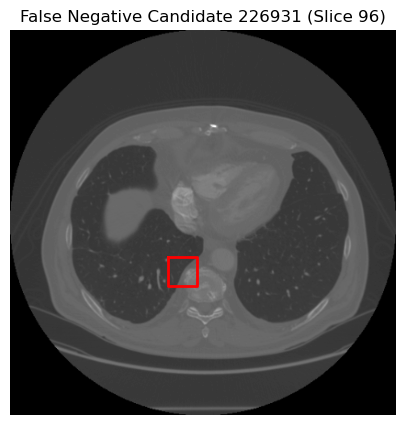

In [83]:
def visualize_random_false_negative_candidate():
    false_negative_candidates = [idx for idx, cand in enumerate(detection_dataset) if cand["strict_label"] == 0]
    
    if not false_negative_candidates:
        print("❌ No false negative candidates found.")
        return
    
    attempt = 0
    while attempt < 10:
        candidate_idx = random.choice(false_negative_candidates)
        candidate = detection_dataset[candidate_idx]
        scan_id = candidate["scan_id"]
        
        scan_path = os.path.join(RESAMPLED_SCANS_DIR, f"{scan_id}_resampled.mhd")
        if not os.path.exists(scan_path):
            attempt += 1
            continue
        
        # Load scan
        scan = sitk.ReadImage(scan_path)
        scan_array = sitk.GetArrayFromImage(scan)
        origin = np.array(scan.GetOrigin())[::-1]    # reverse order: z, y, x
        spacing = np.array(scan.GetSpacing())[::-1]  # reverse order: z, y, x

        # World → Voxel
        center_world = np.array(candidate["center"])  # (z,y,x) in mm
        center_voxel = world_to_voxel(center_world, origin, spacing)

        slice_idx = int(round(center_voxel[0]))
        
        # 🔵 New filter: skip slices too close to edges
        if slice_idx < 10 or slice_idx > scan_array.shape[0] - 10:
            attempt += 1
            continue
        
        slice_idx = np.clip(slice_idx, 0, scan_array.shape[0]-1)
        
        plt.figure(figsize=(10,5))
        plt.imshow(scan_array[slice_idx], cmap="gray")
        
        box_half = 16
        center_y, center_x = center_voxel[1], center_voxel[2]
        
        plt.plot(
            [center_x - box_half, center_x + box_half, center_x + box_half, center_x - box_half, center_x - box_half],
            [center_y - box_half, center_y - box_half, center_y + box_half, center_y + box_half, center_y - box_half],
            color="red", linewidth=2
        )
        
        plt.title(f"False Negative Candidate {candidate_idx} (Slice {slice_idx})")
        plt.axis('off')
        plt.show()
        return
    
    print("❌ Couldn't find a good false negative candidate after 10 attempts.")

   
visualize_random_false_negative_candidate()


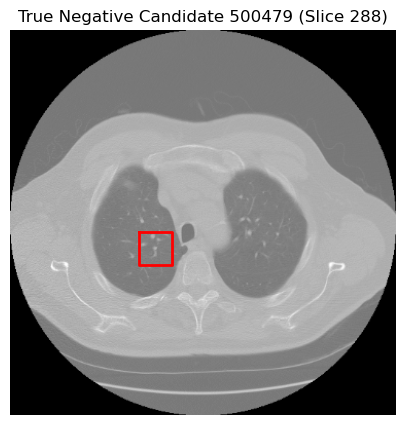

In [103]:
def visualize_random_true_negative_candidate():
    true_negative_candidates = [idx for idx, cand in enumerate(detection_dataset) if cand["strict_label"] == 0]
    
    if not true_negative_candidates:
        print("❌ No true negative candidates found.")
        return
    
    attempt = 0
    while attempt < 10:
        candidate_idx = random.choice(true_negative_candidates)
        candidate = detection_dataset[candidate_idx]
        scan_id = candidate["scan_id"]
        
        scan_path = os.path.join(RESAMPLED_SCANS_DIR, f"{scan_id}_resampled.mhd")
        if not os.path.exists(scan_path):
            attempt += 1
            continue
        
        # Load scan
        scan = sitk.ReadImage(scan_path)
        scan_array = sitk.GetArrayFromImage(scan)
        origin = np.array(scan.GetOrigin())[::-1]    # reverse order: z, y, x
        spacing = np.array(scan.GetSpacing())[::-1]  # reverse order: z, y, x

        # World → Voxel
        center_world = np.array(candidate["center"])  # (z,y,x) in mm
        center_voxel = world_to_voxel(center_world, origin, spacing)

        slice_idx = int(round(center_voxel[0]))
        
        # 🔵 New filter: skip slices too close to edges
        if slice_idx < 10 or slice_idx > scan_array.shape[0] - 10:
            attempt += 1
            continue
        
        slice_idx = np.clip(slice_idx, 0, scan_array.shape[0]-1)
        
        plt.figure(figsize=(10,5))
        plt.imshow(scan_array[slice_idx], cmap="gray")
        
        box_half = 16
        center_y, center_x = center_voxel[1], center_voxel[2]
        
        plt.plot(
            [center_x - box_half, center_x + box_half, center_x + box_half, center_x - box_half, center_x - box_half],
            [center_y - box_half, center_y - box_half, center_y + box_half, center_y + box_half, center_y - box_half],
            color="red", linewidth=2  # Change color to green for true negatives
        )
        
        plt.title(f"True Negative Candidate {candidate_idx} (Slice {slice_idx})")
        plt.axis('off')
        plt.show()
        return
    
    print("❌ Couldn't find a good true negative candidate after 10 attempts.")

   
visualize_random_true_negative_candidate()
